# 手語翻譯 Transformer：Forward Pass + 5～10 筆資料 Overfitting Test

Notebook 上半部保留原本已通過的 Dataset / DataLoader、Transformer、Forward Pass 和單步更新測試；下半部新增**5～10 筆不同影片的過度擬合測試**。

**目標**：確認模型能用不同 Keypoints 產生不同中文標籤，並觀察 Loss、Greedy Decoding 及交換 Keypoints 後的差異。這不是正式的 233 筆訓練或泛化評估。


## 0. 執行前準備

建議把 Notebook 放在**專案根目錄**。如果從根目錄下的其他資料夾執行，程式也會嘗試向上尋找專案根目錄。

需要的套件：`numpy`、`torch`、`jupyter`（或 VS Code 的 Jupyter 擴充套件）。

預期檔案結構：

```text
專案根目錄/
├── rewrite_Phase3_train/
│   └── dataset/
│       ├── manifest.json
│       ├── train.json
│       ├── val.json
│       ├── test.json
│       └── vocab.json
└── yolo_pose_mediapie/
    └── hand_keypoints/
        ├── part_1_1.npy
        └── ...
```

**FPS 設定**：如果現有 `.npy` 是 30 FPS，就把 `FRAME_STEP` 設為 `2`，在讀取時降到約 15 FPS；如果 `.npy` 已是 15 FPS，設為 `1`。此方式預設原始資料採固定 30 FPS。

In [15]:
import json
import math
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

FRAME_STEP = 2       # 30 FPS → 約 15 FPS；若 NPY 已是 15 FPS，改成 1
BATCH_SIZE = 1
PAD_ID = 0

D_MODEL = 192
NHEAD = 4
ENCODER_LAYERS = 3
DECODER_LAYERS = 3
DIM_FF = 512
DROPOUT = 0.2
MAX_LEN = 4096

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'rewrite_Phase3_train' / 'dataset' / 'train.json').is_file()),
    Path.cwd()
)
DATASET_DIR = PROJECT_ROOT / 'rewrite_Phase3_train' / 'dataset'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('專案根目錄:', PROJECT_ROOT)
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

專案根目錄: c:\Users\User\Documents\Push-Github\sign-language
Device: cuda
GPU: NVIDIA GeForce RTX 5060 Ti


## 1. 讀取資料與建立 Dataset

每筆資料包含：

- `keypoints`：形狀 `(T, 128)`，每個 Frame 為左右手的 126 個座標加上 2 個存在狀態。
- `tokens`：形狀 `(L,)`，對應已建立 Vocabulary 的 `<bos>`、文字 Token、`<eos>`。

不同影片的 `T` 和 `L` 可以不一樣。

In [16]:
class SignLanguageDataset(Dataset):
    def __init__(self, json_path, project_root=PROJECT_ROOT, frame_step=FRAME_STEP):
        with open(json_path, 'r', encoding='utf-8') as f:
            self.rows = json.load(f)
        self.project_root = project_root
        self.frame_step = frame_step

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        item = self.rows[idx]
        npy_path = self.project_root / item['npy_path']
        keypoints = np.load(npy_path)[::self.frame_step].astype(np.float32, copy=True)
        tokens = np.asarray(item['token_ids'], dtype=np.int64)

        return torch.from_numpy(keypoints), torch.from_numpy(tokens)


train_dataset = SignLanguageDataset(DATASET_DIR / 'train.json')
val_dataset = SignLanguageDataset(DATASET_DIR / 'val.json')
test_dataset = SignLanguageDataset(DATASET_DIR / 'test.json')

with open(DATASET_DIR / 'vocab.json', 'r', encoding='utf-8') as f:
    vocab = json.load(f)

vocab_size = len(vocab)
print('Training:', len(train_dataset))
print('Validation:', len(val_dataset))
print('Test:', len(test_dataset))
print('Vocabulary Size:', vocab_size)

Training: 233
Validation: 29
Test: 29
Vocabulary Size: 5578


## 2. Dynamic Padding 與 Masks

`collate_fn` 將同一個 Batch 中的序列補到該 Batch 最長的長度：

- `src_key_padding_mask`：標記補齊的 Frame（`True` 表示忽略）。
- `tgt_key_padding_mask`：標記補齊的文字 Token。
- `causal_mask`：阻止 Decoder 在預測下一個 Token 時偷看後面的正確答案。

注意：Source Padding Mask **不是**每個 Frame 最後兩維的「左右手存在狀態」，兩者用途不同。

In [17]:
def collate_fn(batch):
    keypoints, tokens = zip(*batch)

    src_lengths = torch.tensor([len(kp) for kp in keypoints])

    src = pad_sequence(keypoints, batch_first=True, padding_value=0.0)
    tgt = pad_sequence(tokens, batch_first=True, padding_value=PAD_ID)

    src_key_padding_mask = (
        torch.arange(src.size(1))[None, :] >= src_lengths[:, None]
    )

    tgt_in = tgt[:, :-1]
    tgt_out = tgt[:, 1:]
    tgt_key_padding_mask = tgt_in.eq(PAD_ID)

    tgt_length = tgt_in.size(1)
    causal_mask = torch.triu(
        torch.ones((tgt_length, tgt_length), dtype=torch.bool),
        diagonal=1
    )

    return (
        src,
        src_key_padding_mask,
        tgt_in,
        tgt_out,
        tgt_key_padding_mask,
        causal_mask
    )


train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn
)

# 使用固定順序的 DataLoader 進行示範，方便每次確認同一筆樣本
demo_loader = DataLoader(
    train_dataset, batch_size=1, shuffle=False, collate_fn=collate_fn
)

batch = next(iter(demo_loader))
names = [
    'src', 'src_key_padding_mask', 'tgt_in', 'tgt_out',
    'tgt_key_padding_mask', 'causal_mask'
]
for name, tensor in zip(names, batch):
    print(name, tuple(tensor.shape), tensor.dtype)

print('第一筆影片:', train_dataset.rows[0]['video_id'])
print('第一筆中文:', train_dataset.rows[0]['text'][:120])

src (1, 736, 128) torch.float32
src_key_padding_mask (1, 736) torch.bool
tgt_in (1, 67) torch.int64
tgt_out (1, 67) torch.int64
tgt_key_padding_mask (1, 67) torch.bool
causal_mask (67, 67) torch.bool
第一筆影片: part_1_1
第一筆中文: 看新聞 開視野 歡迎收看今天6月6號的公視手語新聞 首先來關心台南市永康鬧區 昨晚突然飄出瓦斯異味 臺南市警消獲報到場偵測到可燃性氣體 緊急疏散周邊店家人員 封路布水線防護 瓦斯公司也關閉閥門 尋找洩漏源 由於今天是上班日 要看搶修進度 才


## 3. 建立 Transformer Encoder-Decoder

架構對應原本《Sign Language Transformer: Implementation Plan》的小型模型建議：

1. `Linear(128 → d_model)` + Positional Encoding
2. Transformer Encoder：學習各 Frame 之間的動作關係
3. Transformer Decoder：結合已知文字與 Encoder 特徵（Cross-Attention）
4. `Linear(d_model → vocab_size)`：輸出每個文字位置的詞彙預測分數

`MAX_LEN=4096` 用來容納預期的 15 FPS 長序列；這**不代表**所有這麼長的序列都一定能放進 GPU 記憶體。

In [18]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=4096):
        super().__init__()

        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(
            torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class SignTransformer(nn.Module):
    def __init__(
        self, vocab_size, kp_dim=128, d_model=192, nhead=4,
        num_encoder_layers=3, num_decoder_layers=3,
        dim_ff=512, dropout=0.2, pad_id=0, max_len=4096
    ):
        super().__init__()

        self.input_proj = nn.Linear(kp_dim, d_model)
        self.tgt_embed = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.pos_enc = PositionalEncoding(d_model, max_len=max_len)

        self.encoder = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=nhead,
                dim_feedforward=dim_ff,
                dropout=dropout,
                batch_first=True
            ),
            num_layers=num_encoder_layers
        )

        self.decoder = nn.TransformerDecoder(
            nn.TransformerDecoderLayer(
                d_model=d_model,
                nhead=nhead,
                dim_feedforward=dim_ff,
                dropout=dropout,
                batch_first=True
            ),
            num_layers=num_decoder_layers
        )

        self.output_proj = nn.Linear(d_model, vocab_size)

    def forward(
        self, src, tgt_in, src_key_padding_mask,
        tgt_key_padding_mask, causal_mask
    ):
        src = self.pos_enc(self.input_proj(src))
        memory = self.encoder(
            src, src_key_padding_mask=src_key_padding_mask
        )

        tgt = self.pos_enc(self.tgt_embed(tgt_in))
        decoded = self.decoder(
            tgt,
            memory,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=tgt_key_padding_mask,
            memory_key_padding_mask=src_key_padding_mask
        )
        return self.output_proj(decoded)


model = SignTransformer(
    vocab_size=vocab_size,
    d_model=D_MODEL,
    nhead=NHEAD,
    num_encoder_layers=ENCODER_LAYERS,
    num_decoder_layers=DECODER_LAYERS,
    dim_ff=DIM_FF,
    dropout=DROPOUT,
    pad_id=PAD_ID,
    max_len=MAX_LEN
).to(device)

print('模型參數數量:', f'{sum(p.numel() for p in model.parameters()):,}')

模型參數數量: 4,695,946


## 4. 第一次 Forward Pass（不更新模型參數）

這一步只檢查 Encoder / Decoder 是否能成功運算。

正確的輸出格式應為 `(Batch Size, Target Length, Vocabulary Size)`；Vocabulary Size 取自你自己的 `vocab.json`，不是固定 2000。

In [19]:
src, src_kpm, tgt_in, tgt_out, tgt_kpm, causal = [
    tensor.to(device) for tensor in batch
]

model.eval()
with torch.no_grad():
    logits = model(src, tgt_in, src_kpm, tgt_kpm, causal)

print('Device:', device)
print('Input Shape:', tuple(src.shape))
print('Target Shape:', tuple(tgt_in.shape))
print('Output Shape:', tuple(logits.shape))
print('Vocabulary Size:', vocab_size)
print('輸出維度正確:', logits.shape == (src.size(0), tgt_in.size(1), vocab_size))

Device: cuda
Input Shape: (1, 736, 128)
Target Shape: (1, 67)
Output Shape: (1, 67, 5578)
Vocabulary Size: 5578
輸出維度正確: True


## 5. 確認初始 Loss

使用 Cross-Entropy Loss，比較 Decoder 輸出與 `tgt_out`。由於還沒有訓練，Loss 不會有特別低的期待值。

In [20]:
criterion = nn.CrossEntropyLoss(
    ignore_index=PAD_ID,
    label_smoothing=0.1
)

with torch.no_grad():
    initial_loss = criterion(
        logits.reshape(-1, logits.size(-1)),
        tgt_out.reshape(-1)
    )

print('初始 Loss:', f'{initial_loss.item():.4f}')

初始 Loss: 8.9100


## 6. 可選：測試一次反向傳播（預設關閉）

如果要確認梯度和 AdamW 能正常運作，把 `RUN_ONE_TRAIN_STEP = True`。它只更新 **1 個 Batch**，不是正式訓練。長影片可能需要較多 GPU 記憶體，請先確保 Forward Pass 成功。

In [21]:
RUN_ONE_TRAIN_STEP = False

if RUN_ONE_TRAIN_STEP:
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4)
    model.train()

    optimizer.zero_grad()
    logits_train = model(src, tgt_in, src_kpm, tgt_kpm, causal)
    train_loss = criterion(
        logits_train.reshape(-1, logits_train.size(-1)),
        tgt_out.reshape(-1)
    )
    train_loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()

    print('單步訓練 Loss:', f'{train_loss.item():.4f}')
else:
    print('已略過單步反向傳播。')

已略過單步反向傳播。


## 7. 多筆 Overfitting Test（新增）

接下來會從 **Training Set** 中挑選 5～10 筆較短、文字不重複的完整影片。短片段只是為了讓第一輪除錯更容易，**不會切掉任何 Frame 或任何中文標籤**。

為了清楚驗證能否記住小樣本，這個測試會建立**全新模型**、將 Dropout 設為 0、關閉 Label Smoothing，並以 Batch Size 1 反覆訓練。原有單筆測試的模型不會被用於這個實驗。

注意：`FRAME_STEP=2` 代表假設原始 `.npy` 為 30 FPS，讀取後約 15 FPS。若 `.npy` 本身已是 15 FPS，請回到最上面設定 `FRAME_STEP=1`。


### 7.1 設定測試參數

先用 **5 筆、100 Epochs** 測試。想擴大可把 `OVERFIT_SAMPLES=10`。正式訓練時不要沿用這裡的 `DROPOUT=0` 設定。

In [22]:
import random
import matplotlib.pyplot as plt
from torch.utils.data import Subset

OVERFIT_SAMPLES = 10       # 可改成 10
OVERFIT_EPOCHS = 100     # 不夠時可增加
OVERFIT_LR = 3e-4
OVERFIT_SEED = 42
OVERFIT_STOP_LOSS = 0.01
PRINT_EVERY = 10

TEST_D_MODEL = 128
TEST_NHEAD = 4
TEST_ENCODER_LAYERS = 2
TEST_DECODER_LAYERS = 2
TEST_DIM_FF = 256
TEST_DROPOUT = 0.0

random.seed(OVERFIT_SEED)
np.random.seed(OVERFIT_SEED)
torch.manual_seed(OVERFIT_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(OVERFIT_SEED)

print('裝置:', device)
print('測試影片數:', OVERFIT_SAMPLES)


裝置: cuda
測試影片數: 10


### 7.2 從 Training Set 挑選 5～10 筆不同文字的影片

使用 `.npy` 的形狀快速排序影片長度（只讀檔案資訊，不載入整部影片）。挑選較短影片以降低初期測試的記憶體需求。**不會使用 Validation / Test 進行這項過度擬合測試。**

In [23]:
sample_info = []

for idx, row in enumerate(train_dataset.rows):
    file_path = PROJECT_ROOT / row['npy_path']
    original_frames = np.load(file_path, mmap_mode='r').shape[0]
    frames_after_sampling = (original_frames + FRAME_STEP - 1) // FRAME_STEP
    sample_info.append({
        'idx': idx,
        'video_id': row['video_id'],
        'text': row['text'],
        'frames': frames_after_sampling,
        'tokens': len(row['token_ids']) - 1
    })

sample_info.sort(key=lambda x: (x['frames'], x['tokens']))
selected_info = []
seen_texts = set()

for item in sample_info:
    if item['text'] in seen_texts:
        continue
    if item['frames'] > MAX_LEN or item['tokens'] > MAX_LEN:
        continue
    selected_info.append(item)
    seen_texts.add(item['text'])
    if len(selected_info) == OVERFIT_SAMPLES:
        break

assert len(selected_info) == OVERFIT_SAMPLES, '訓練集中符合條件且文字不同的影片不足'

selected_indices = [item['idx'] for item in selected_info]
overfit_dataset = Subset(train_dataset, selected_indices)
overfit_loader = DataLoader(
    overfit_dataset,
    batch_size=1,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0
)

for item in selected_info:
    print(f"{item['video_id']}: {item['frames']} Frames, {item['tokens']} Target Tokens")
    print(' ', item['text'][:90])


part_11_2: 235 Frames, 32 Target Tokens
  整艘被強風吹到馬路上 市區加油站的屋頂被吹垮 連縣政府和醫院的玻璃門 也不敵風勢整片碎裂 狂風暴雨直接橫掃室內
part_31_4: 252 Frames, 26 Target Tokens
  臉書社團傳出了災情 星期二晚間開始 大量臉書社團被無預警停用 初步調查主要是技術問題 已經開始修復
part_20_2: 256 Frames, 28 Target Tokens
  柯文哲昨天晚上7點左右 離開了新竹老家 返回台北住處 面對媒體詢問 如何看待北檢要提抗告 柯文哲是不發一語 沒有回應
part_2_11: 274 Frames, 43 Target Tokens
  夏天到了有些聽障朋友喜歡嘗試 不揹氧氣瓶的自由潛水 而競技自由潛水則是只憑著一口氣 在水下比賽憋氣長短和潛水深度的活動 帶您一起去看看
part_28_8: 310 Frames, 28 Target Tokens
  一年一度南投日月潭萬人泳渡昨天登場 共有2萬4千多人報名 其中包括130名的身障泳者 他們也全部完成泳渡的壯舉
part_2_10: 313 Frames, 45 Target Tokens
  這幾天都是高溫炎熱的天氣型態 昨天在桃園蘆竹測到了39.2度高溫 另外在新北三峽和金門測站也有超過38度 根據衛福部統計 7月1號2號這兩天 因為熱傷害就診就超過百人
part_32_5: 314 Frames, 45 Target Tokens
  被逆向毒駕的男子黃國維衝撞殉職 昨天新北地方法院一審宣判 國民法官判處黃國維 18年6個月的重刑 全案還可以上訴 而對於被告在法庭上毫無悔意 家屬是感到相當痛心
part_16_4: 329 Frames, 30 Target Tokens
  核三重啟公投明天登場 而美國總統川普 20號在社群發文 批評風力和太陽能發電 是世紀最大騙局 將不再批准太陽能電廠建設案
part_28_9: 335 Frames, 43 Target Tokens
  第31屆亞洲棒球錦標賽冠軍戰 台灣昨天晚間再度與日本交手 結果日本攻勢猛烈 全場狂敲了15支的安打 終場台灣就以0比11落敗 屈居亞軍 還寫下冠軍戰比數最大分差紀錄
part_20_8: 339 Frames, 3

### 7.3 重新初始化模型與 Optimizer

這裡刻意建立 `overfit_model`，不會繼承你之前對單筆資料訓練的權重。Loss 使用一般 Cross-Entropy（無 Label Smoothing）。

In [24]:
overfit_model = SignTransformer(
    vocab_size=vocab_size,
    d_model=TEST_D_MODEL,
    nhead=TEST_NHEAD,
    num_encoder_layers=TEST_ENCODER_LAYERS,
    num_decoder_layers=TEST_DECODER_LAYERS,
    dim_ff=TEST_DIM_FF,
    dropout=TEST_DROPOUT,
    pad_id=PAD_ID,
    max_len=MAX_LEN
).to(device)

overfit_optimizer = torch.optim.AdamW(
    overfit_model.parameters(), lr=OVERFIT_LR
)

print('新模型參數數量:', f'{sum(p.numel() for p in overfit_model.parameters()):,}')


新模型參數數量: 2,112,586


### 7.4 反覆訓練這幾筆資料

每個 Epoch 都會看到這 5～10 筆影片各一次。Loss 按有效 Token 數量加權平均，避免不同長度句子的 Loss 被不公平地計算。Loss 低於設定門檻會提早結束，但之後仍需要看實際生成文字。

In [25]:
loss_history = []

for epoch in range(1, OVERFIT_EPOCHS + 1):
    overfit_model.train()
    total_loss = 0.0
    total_tokens = 0

    for batch_data in overfit_loader:
        src_b, src_mask_b, tgt_in_b, tgt_out_b, tgt_mask_b, causal_b = [
            tensor.to(device) for tensor in batch_data
        ]

        overfit_optimizer.zero_grad()
        logits_b = overfit_model(
            src_b, tgt_in_b, src_mask_b, tgt_mask_b, causal_b
        )

        valid_tokens = (tgt_out_b != PAD_ID).sum()
        loss_sum = nn.functional.cross_entropy(
            logits_b.reshape(-1, vocab_size),
            tgt_out_b.reshape(-1),
            ignore_index=PAD_ID,
            reduction='sum'
        )
        loss = loss_sum / valid_tokens

        loss.backward()
        torch.nn.utils.clip_grad_norm_(overfit_model.parameters(), max_norm=1.0)
        overfit_optimizer.step()

        total_loss += loss_sum.item()
        total_tokens += valid_tokens.item()

    epoch_loss = total_loss / total_tokens
    loss_history.append(epoch_loss)

    if epoch == 1 or epoch % PRINT_EVERY == 0:
        print(f'Epoch {epoch:3d}: Training Loss = {epoch_loss:.4f}')

    if epoch_loss < OVERFIT_STOP_LOSS:
        print(f'達到 Loss 門檻，提早停止於 Epoch {epoch}')
        break

print(f'最後 Training Loss: {loss_history[-1]:.4f}')


Epoch   1: Training Loss = 8.6769
Epoch  10: Training Loss = 5.3768
Epoch  20: Training Loss = 2.8611
Epoch  30: Training Loss = 1.1910
Epoch  40: Training Loss = 0.3182
Epoch  50: Training Loss = 0.1003
Epoch  60: Training Loss = 0.0564
Epoch  70: Training Loss = 0.0363
Epoch  80: Training Loss = 0.0264
Epoch  90: Training Loss = 0.0203
Epoch 100: Training Loss = 0.0162
最後 Training Loss: 0.0162


### 7.5 觀察 Training Loss 曲線

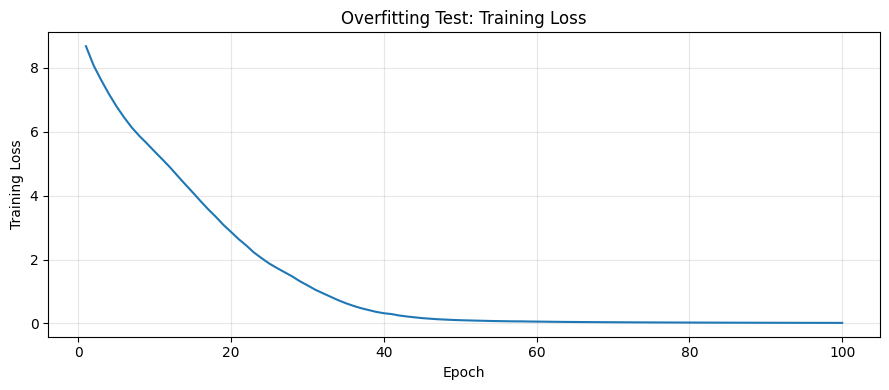

In [26]:
plt.figure(figsize=(9, 4))
plt.plot(range(1, len(loss_history) + 1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.title('Overfitting Test: Training Loss')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 7.6 對每筆影片進行 Greedy Decoding

與 Teacher Forcing 不同，這裡只給 Decoder `<bos>`，之後的 Token 都由模型自己決定。

為了避免重複運算，**每筆影片的 Encoder 只執行一次**，接著由 Decoder 逐字詞輸出。檢查的是 Token IDs 完全一致與否，文字比較也會顯示。

In [27]:
BOS_ID = vocab['<bos>']
EOS_ID = vocab['<eos>']
ID_TO_TOKEN = {value: key for key, value in vocab.items()}


def normalize_output_ids(ids):
    result = [int(i) for i in ids]
    if result and result[0] == BOS_ID:
        result = result[1:]
    if EOS_ID in result:
        result = result[:result.index(EOS_ID) + 1]
    return result


def token_ids_to_text(ids):
    return ''.join(
        ID_TO_TOKEN.get(int(i), '<unk>')
        for i in ids if int(i) not in (BOS_ID, EOS_ID, PAD_ID)
    )


@torch.no_grad()
def greedy_decode(model, src, src_padding_mask, max_new_tokens):
    model.eval()
    encoded = model.pos_enc(model.input_proj(src))
    memory = model.encoder(encoded, src_key_padding_mask=src_padding_mask)
    generated = torch.full(
        (src.shape[0], 1), BOS_ID, dtype=torch.long, device=src.device
    )

    for _ in range(max_new_tokens):
        length = generated.size(1)
        tgt_mask = torch.triu(
            torch.ones((length, length), device=src.device, dtype=torch.bool),
            diagonal=1
        )
        tgt_emb = model.pos_enc(model.tgt_embed(generated))
        decoded = model.decoder(
            tgt_emb,
            memory,
            tgt_mask=tgt_mask,
            memory_key_padding_mask=src_padding_mask
        )
        next_id = model.output_proj(decoded[:, -1:, :]).argmax(dim=-1)
        generated = torch.cat([generated, next_id], dim=1)
        if torch.all(next_id == EOS_ID):
            break

    return generated[0].tolist()


results = []
for item in selected_info:
    src_one, target_all = train_dataset[item['idx']]
    src_one = src_one.unsqueeze(0).to(device)
    src_padding_mask = torch.zeros(
        (1, src_one.size(1)), dtype=torch.bool, device=device
    )

    target_ids = normalize_output_ids(target_all.tolist())
    prediction_all = greedy_decode(
        overfit_model, src_one, src_padding_mask, max_new_tokens=len(target_ids) + 20
    )
    predicted_ids = normalize_output_ids(prediction_all)
    exact_match = predicted_ids == target_ids
    results.append({'video_id': item['video_id'], 'match': exact_match})

    print(f"\n影片: {item['video_id']}")
    print('正確文字:', token_ids_to_text(target_all.tolist()))
    print('模型預測:', token_ids_to_text(prediction_all))
    print('Token IDs 完全一致:', exact_match)

print(f"\n完全一致: {sum(r['match'] for r in results)} / {len(results)}")



影片: part_11_2
正確文字: 整艘被強風吹到馬路上市區加油站的屋頂被吹垮連縣政府和醫院的玻璃門也不敵風勢整片碎裂狂風暴雨直接橫掃室內
模型預測: 整艘被強風吹到馬路上市區加油站的屋頂被吹垮連縣政府和醫院的玻璃門也不敵風勢整片碎裂狂風暴雨直接橫掃室內
Token IDs 完全一致: True

影片: part_31_4
正確文字: 臉書社團傳出了災情星期二晚間開始大量臉書社團被無預警停用初步調查主要是技術問題已經開始修復
模型預測: 臉書社團傳出了災情星期二晚間開始大量臉書社團被無預警停用初步調查主要是技術問題已經開始修復
Token IDs 完全一致: True

影片: part_20_2
正確文字: 柯文哲昨天晚上7點左右離開了新竹老家返回台北住處面對媒體詢問如何看待北檢要提抗告柯文哲是不發一語沒有回應
模型預測: 柯文哲昨天晚上7點左右離開了新竹老家返回台北住處面對媒體詢問如何看待北檢要提抗告柯文哲是不發一語沒有回應
Token IDs 完全一致: True

影片: part_2_11
正確文字: 夏天到了有些聽障朋友喜歡嘗試不揹氧氣瓶的自由潛水而競技自由潛水則是只憑著一口氣在水下比賽憋氣長短和潛水深度的活動帶您一起去看看
模型預測: 夏天到了有些聽障朋友喜歡嘗試不揹氧氣瓶的自由潛水而競技自由潛水則是只憑著一口氣在水下比賽憋氣長短和潛水深度的活動帶您一起去看看
Token IDs 完全一致: True

影片: part_28_8
正確文字: 一年一度南投日月潭萬人泳渡昨天登場共有2萬4千多人報名其中包括130名的身障泳者他們也全部完成泳渡的壯舉
模型預測: 一年一度南投日月潭萬人泳渡昨天登場共有2萬4千多人報名其中包括130名的身障泳者他們也全部完成泳渡的壯舉
Token IDs 完全一致: True

影片: part_2_10
正確文字: 這幾天都是高溫炎熱的天氣型態昨天在桃園蘆竹測到了39.2度高溫另外在新北三峽和金門測站也有超過38度根據衛福部統計7月1號2號這兩天因為熱傷害就診就超過百人
模型預測: 這幾天都是高溫炎熱的天氣型態昨天在桃園蘆竹測到了39.2度高溫另外在新北三峽和金門測站也有超過38度根據衛福部統計7月1號2號這兩天因為熱傷害就診就超過百人
Token IDs 完全一致: True

影片: part_32_5
正確文

### 7.7 交換 Keypoints 測試：模型是否使用視覺輸入？

固定每筆資料自己的中文標籤，對照兩種輸入的 **Teacher-forced Cross-Entropy**：

- **原始**：Keypoints A + 文字 A
- **交換**：Keypoints B + 文字 A（B 是清單中的下一支影片，最後一支使用第一支）

如果交換輸入後 Loss 沒有明顯升高，可能表示模型主要依賴已知的前文 Token，而不是利用手語特徵。即使交換後 Loss 上升，也只是**初步依賴性檢查**，不是翻譯能力的證明。

In [28]:
@torch.no_grad()
def teacher_forced_loss(model, src, target_ids):
    model.eval()
    tokens = torch.tensor(target_ids, dtype=torch.long, device=device)
    src = src.unsqueeze(0).to(device)
    target_in = tokens[:-1].unsqueeze(0)
    target_out = tokens[1:].unsqueeze(0)
    length = target_in.size(1)
    causal = torch.triu(
        torch.ones((length, length), device=device, dtype=torch.bool),
        diagonal=1
    )
    src_mask = torch.zeros((1, src.size(1)), device=device, dtype=torch.bool)
    logits = model(src, target_in, src_mask, target_in == PAD_ID, causal)
    return nn.functional.cross_entropy(
        logits.reshape(-1, vocab_size), target_out.reshape(-1),
        ignore_index=PAD_ID
    ).item()


original_losses = []
swapped_losses = []

for i, item in enumerate(selected_info):
    same_src, same_tokens = train_dataset[item['idx']]
    other_item = selected_info[(i + 1) % len(selected_info)]
    other_src, _ = train_dataset[other_item['idx']]

    normal = teacher_forced_loss(overfit_model, same_src, same_tokens.tolist())
    swapped = teacher_forced_loss(overfit_model, other_src, same_tokens.tolist())
    original_losses.append(normal)
    swapped_losses.append(swapped)

    print(f"{item['video_id']}: 原始 Loss={normal:.4f}, 交換 Loss={swapped:.4f} ({other_item['video_id']} 的 Keypoints)")

print(f'\n平均原始 Loss: {np.mean(original_losses):.4f}')
print(f'平均交換 Loss: {np.mean(swapped_losses):.4f}')


part_11_2: 原始 Loss=0.0145, 交換 Loss=0.4032 (part_31_4 的 Keypoints)
part_31_4: 原始 Loss=0.0124, 交換 Loss=0.3987 (part_20_2 的 Keypoints)
part_20_2: 原始 Loss=0.0140, 交換 Loss=0.4821 (part_2_11 的 Keypoints)
part_2_11: 原始 Loss=0.0177, 交換 Loss=0.3479 (part_28_8 的 Keypoints)
part_28_8: 原始 Loss=0.0132, 交換 Loss=0.3705 (part_2_10 的 Keypoints)
part_2_10: 原始 Loss=0.0178, 交換 Loss=0.3624 (part_32_5 的 Keypoints)
part_32_5: 原始 Loss=0.0183, 交換 Loss=0.4020 (part_16_4 的 Keypoints)
part_16_4: 原始 Loss=0.0146, 交換 Loss=0.3755 (part_28_9 的 Keypoints)
part_28_9: 原始 Loss=0.0178, 交換 Loss=0.1934 (part_20_8 的 Keypoints)
part_20_8: 原始 Loss=0.0150, 交換 Loss=0.4365 (part_11_2 的 Keypoints)

平均原始 Loss: 0.0155
平均交換 Loss: 0.3772


## 如何解讀結果？

1. **Loss 下降 + 5/5 Greedy Decoding 完全一致**：表示模型能記住 5 筆影片的文字映射，資料流程大致可用。
2. **Loss 很低、Greedy Decoding 卻出錯**：Teacher Forcing 期間的逐步預測與真正自行生成有落差，需要繼續測試。
3. **交換 Keypoints 後 Loss 幾乎不變**：值得懷疑模型主要靠文字前文記憶；需要更多資料、不同輸入擾動或進一步對照實驗。
4. **上述測試都成功，也不等於已具備手語翻譯泛化能力**：必須用獨立 Validation / Test 影片測試，並特別注意完整影片與字幕的配對品質。

**注意：** 這個 Notebook 只是小樣本診斷。正式訓練請重新設計 Epoch 訓練、驗證、Checkpoint、Early Stopping，並使用適當的 Dropout 和資料切分。